In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

words = open('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(words))))
char_to_int = {char: idx + 1 for idx, char in enumerate(chars)}
char_to_int['.'] = 0
int_to_char = {idx:char for char,idx in char_to_int.items()}

block_size = 3
x_context, y_outputs = [], []

for w in words:

    context = [0]* block_size
    for ch in w + '.':
        ix = char_to_int[ch]
        x_context.append(context)
        y_outputs.append(ix)
        context = context[1:] + [ix]

x_context = torch.tensor(x_context)
y_outputs = torch.tensor(y_outputs)

g = torch.Generator().manual_seed(2147483647)
embeddings_table = torch.randn((27,2), generator=g)
weights1 = torch.randn((6,100), generator=g)
bias1 = torch.randn(100, generator=g)
weights2 = torch.randn((100,27), generator=g)
bias2 = torch.randn(27, generator=g)
parameters = [embeddings_table, weights1, bias1, weights2, bias2]

for p in parameters:
    p.requires_grad = True

In [2]:
lre = torch.linspace(-3,0,1000)
lrs=10**lre
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [3]:
import time

lri = [] # learning_rate for i
lossi = [] #loss for i

# You have 228,146 questions of the form "here are 3 letters, what comes next?"
# Looking at all of them every step is slow.
# Each step grabs 32 questions at random and asks one thing: on these 32, how wrong am I?

# The overall loss is the average of 228,146 separate little losses, one per question. Pick 32 of those little losses at random and average them. You get a rough copy of the big average. One draw might read 2.4 when the real average is 2.7. The next draw might read 3.1. The copy wobbles. It is still a reading of the same thing.

for __ in range(1):
    for i in range(1000):

        # minibatch
        ix = torch.randint(low=0, high=x_context.shape[0],size=(32,)) # random 32 numbers

        #forward pass
        emb = embeddings_table[x_context[ix]]
        h = torch.tanh(emb.view(-1,6)@weights1+bias1)
        logits = h @ weights2 + bias2
        loss = F.cross_entropy(input=logits, target=y_outputs[ix])

        for p in parameters:
            p.grad = None

        loss.backward()

        lr = lrs[i]
        for p in parameters:
            p.data += -lr*p.grad

        lri.append(lre[i])
        lossi.append(loss.item())

    # emb = embeddings_table[x_context]
    # h = torch.tanh(emb.view(-1,6)@weights1+bias1)
    # logits=h@weights2+bias2
    # loss = F.cross_entropy(logits,y_outputs)
    # print(loss)

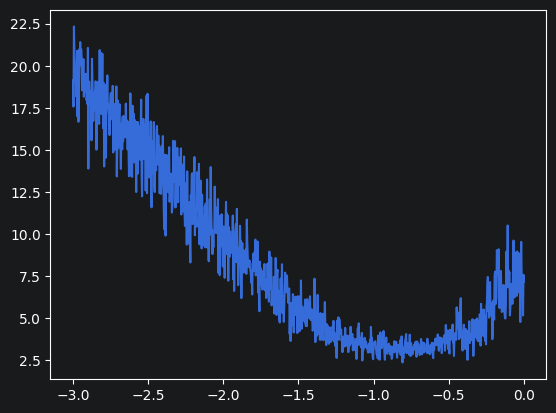

In [4]:
plt.plot(lri, lossi) # so the right learning rate is around 0.1

# we could use 0.1 and at the end 0.01 DECAY learning rate
# but a perfectly optimized  = overfitting
# that's why we need to split the data

In [7]:
ix = torch.randint(low=0, high=x_context.shape[0],size=(32,))
ix

tensor([222694, 100292,  74970, 169470, 119789, 173444, 177085, 137849, 226268,
         20375,  21848, 193957,  48849,  98605, 188652, 179727,  72830, 163252,
        216193, 167116, 222897, 167304, 116196, 226039,  59608, 162436, 227230,
         99026, 142647, 215541,   9977,  70378])

In [6]:
print(x_context.shape[0])

228146
